In [2]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np

from spectre import SPECTREout

%load_ext autoreload
%autoreload 2

%matplotlib ipympl

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [6]:
out_obj = SPECTREout("fixb_7vol.h5")

In [12]:
# Initialize Poincare plot with trajectories regularly spaced between interfaces along \t=0,
# like in poincare_mod.F90

num_transits = 500
num_trajectories = 5

init_pts = [
    np.array(
        [
            [(-1.0 + 1e-14) + itrj * (2.0 - 2e-14) / num_trajectories, 0.0]
            for itrj in range(0 if j > 0 else 1, num_trajectories + 1)
        ]
    )
    for j in range(out_obj.input.physics.Mvol)
]

num_phi_planes = out_obj.poincare.R.shape[2]

out_obj.trace_fieldlines(
    init_pts,
    num_phi_planes=num_phi_planes,
    num_transits=num_transits,
    method="RK45",
    rtol=1.0e-7,
    atol=1.0e-7,
)

Rank 0: done volume 0
Rank 0: done volume 1
Rank 0: done volume 2
Rank 0: done volume 3
Rank 0: done volume 4
Rank 0: done volume 5
Rank 0: done volume 6
Poincare trace completed (12.76s)


Normalized zetas: [0.         0.02083333 0.04166667 0.0625     0.08333333 0.10416667
 0.125      0.14583333 0.16666667 0.1875     0.20833333 0.22916667
 0.25       0.27083333 0.29166667 0.3125     0.33333333 0.35416667
 0.375      0.39583333 0.41666667 0.4375     0.45833333 0.47916667
 0.5        0.52083333 0.54166667 0.5625     0.58333333 0.60416667
 0.625      0.64583333 0.66666667 0.6875     0.70833333 0.72916667
 0.75       0.77083333 0.79166667 0.8125     0.83333333 0.85416667
 0.875      0.89583333 0.91666667 0.9375     0.95833333 0.97916667]


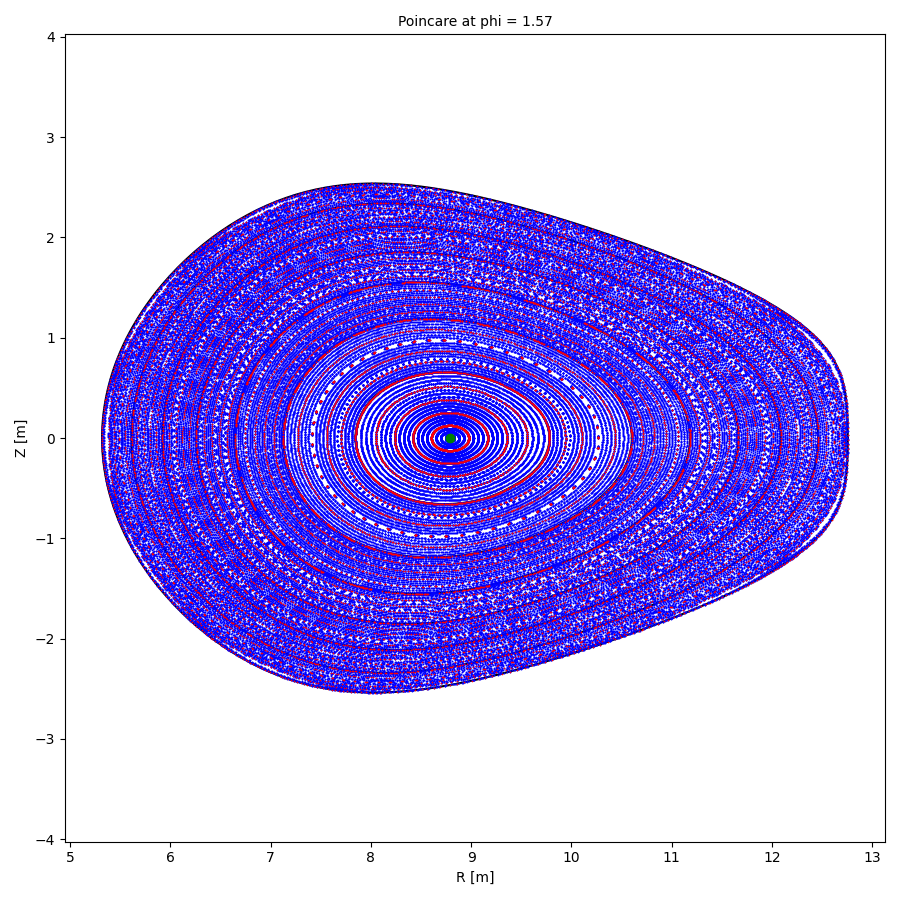

In [16]:
# Plot results, and compare to old poincare

zetan = 0.5

fig, ax = plt.subplots(1, 1, figsize=(9, 9))
out_obj.plot_infaces(ax=ax, color="k", zetan=zetan, prange="full")
out_obj.plot_poincare(ax=ax, c="blue", zetan=zetan, ms=1.4, prange="full")
out_obj.tracer.plot(ax=ax, c="red", zetan=zetan, ms=1.2, prange="full")

r,z,_,_ = out_obj.find_axis(zetan=zetan)
ax.plot(r, z, 'go')

plt.tight_layout()

In [28]:
# Now do Poincare but start with RZ initial points
# And start the poincare at zetan=0.5

num_transits = 300
num_phi_planes = out_obj.poincare.R.shape[2]

init_r = np.linspace(7,11,7)
init_z = np.linspace(-1.5,1.5,6)
init_rz = np.meshgrid(init_r, init_z)
init_rz = np.array([init_rz[0].flatten(), init_rz[1].flatten()]).T

out_obj.trace_fieldlines_fromrz(init_rz, zetan_start=0.5, num_transits=num_transits, num_phi_planes=num_phi_planes)

Rank 0: done volume 0
Rank 0: done volume 1
Rank 0: done volume 2
Rank 0: done volume 3
Rank 0: done volume 4
Rank 0: done volume 5
Poincare trace completed (8.21s)


array([[[ 7.        ,  6.94538846,  6.90916661, ...,  6.63771643,
          6.54991147,  6.48034474],
        [-1.5       , -1.66255831, -1.82882079, ..., -0.3598577 ,
         -0.52693514, -0.69716052]],

       [[ 7.66666667,  7.61649956,  7.58548915, ...,  9.24730668,
          9.12100046,  9.01892131],
        [-1.5       , -1.65359731, -1.80947356, ..., -1.20881014,
         -1.32849158, -1.45568702]],

       [[ 8.33333333,  8.28328653,  8.25369714, ..., 11.11320126,
         11.04316976, 10.98965833],
        [-1.5       , -1.64514737, -1.79211539, ..., -0.32816337,
         -0.36241799, -0.40447879]],

       ...,

       [[ 9.66666667,  9.7496178 ,  9.85660096, ...,  9.1345796 ,
          9.15040657,  9.18759727],
        [ 1.5       ,  1.38760941,  1.28480434, ...,  2.01713988,
          1.88153056,  1.74769693]],

       [[10.33333333, 10.4267062 , 10.54356782, ..., 11.24603026,
         11.25698489, 11.28937286],
        [ 1.5       ,  1.41343951,  1.34241241, ...,  1.06838

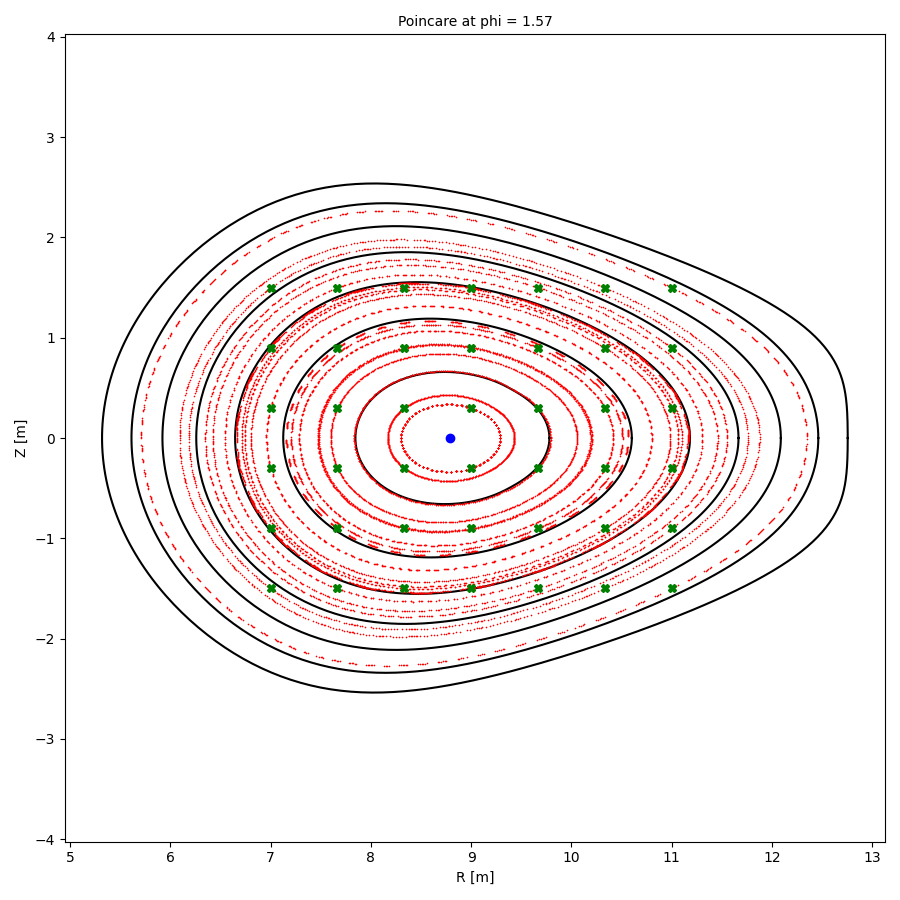

In [31]:
# Plot results, and compare to old poincare

zetan = 0.5

fig, ax = plt.subplots(1, 1, figsize=(9, 9))
out_obj.plot_infaces(ax=ax, color="k", zetan=zetan, prange="full")
# out_obj.plot_poincare(ax=ax, c="blue", zetan=zetan, ms=1.4, prange="full")
out_obj.tracer.plot(ax=ax, c="red", zetan=zetan, ms=1.2, prange="full")

ax.plot(init_rz.T[0], init_rz.T[1], 'gX', ms=6)

r,z,_,_ = out_obj.find_axis(zetan=zetan)
ax.plot(r, z, 'bo')

plt.tight_layout()